# 05 — KFold aléatoire, groupes et modèles exportés

Configuration de travail demandée : **16 entrées numériques + procédé**, médiane.
Charpy ajoute sa température connue ; quatre régressions séparées. Même cohorte
strict13 que 03/04 : ajouter des colonnes ne crée pas d'observations. COREG n'est
pas exécuté ici : splits et accès aux pools sont préparés pour la suite.

Méthode avant calcul : auditer les répétitions et les groupes inférés, comparer un
RF fixe sous trois découpages, puis entraîner baseline/Ridge/SVR/RF/kNN avec
KFold mélangé 5 plis externes/3 internes. **Famille et paramètres sont sélectionnés
sur MAE interne** ; les labels externes servent à l'évaluation. Les préparations
sont ajustées sur chaque train. Les essais restent rétrospectifs après 03/04.

Un R² aléatoire élevé n'établit pas l'hypothèse IID. Le scénario aléatoire mesure
l'interpolation entre lignes de la base ; le scénario par séries mesure le
transfert vers des séries absentes du train. Les groupes dérivés d'IDs peuvent
être plus larges qu'une soudure ; les deux questions restent documentées.
[Référence CV scikit-learn](https://scikit-learn.org/stable/modules/cross_validation.html).


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.exceptions import ConvergenceWarning
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.linear_model import BayesianRidge, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, ParameterGrid
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from joblib import Memory, parallel_config
from threadpoolctl import threadpool_limits

SEED = 42
N_JOBS = 3  # recherches parallèles ; chaque forêt utilise un seul worker
PRIMARY_SET = 'A1b_16'
PRIMARY_IMPUTER = 'median'
TARGETS = ['yield_strength', 'uts', 'elongation', 'charpy_J']
CAT = 'weld_process'
PROCESS_COL = CAT
CORE13 = ['C', 'Si', 'Mn', 'S', 'P', 'current_A', 'voltage_V',
          'heat_input_kJmm', 'interpass_C', 'pwht_temp_C', 'pwht_time_h',
          'O_ppm', 'N_ppm']
CORE16 = CORE13 + ['Ni', 'Cr', 'Mo']
NONNEG = CORE16  # la température d'essai peut être négative
TARGET_UNITS = {'yield_strength': 'MPa', 'uts': 'MPa',
                'elongation': 'points de %', 'charpy_J': 'J'}
TARGET_NAMES = {'yield_strength': "Limite d'élasticité", 'uts': 'Résistance maximale',
                'elongation': 'Allongement', 'charpy_J': 'Énergie Charpy — exploratoire'}
MODEL_NAMES = {'median_y': 'Médiane de y', 'ridge': 'Ridge', 'svr_rbf': 'SVR RBF',
               'random_forest': 'Random Forest', 'knn': 'kNN'}
PARAM_GRIDS = {
    'median_y': {},
    'ridge': {'model__alpha': [0.01, 0.1, 1, 10, 100, 1000]},
    'svr_rbf': {'model__regressor__C': [1, 10, 100],
                'model__regressor__gamma': ['scale', 0.05],
                'model__regressor__epsilon': [0.05, 0.2]},
    'random_forest': {'model__min_samples_leaf': [1, 2, 5],
                     'model__max_depth': [None, 10],
                     'model__max_features': [0.5, 1.0]},
    'knn': {'model__n_neighbors': [3, 5, 9, 15], 'model__p': [1, 2]},
}

def numeric_features(target):
    if target not in TARGETS:
        raise ValueError(f'Cible non prévue : {target}')
    return list(CORE16) + (['charpy_temp_C'] if target == 'charpy_J' else [])

def task_features(target):
    return numeric_features(target) + [CAT]

def eligible_rows(frame, target):
    # La température d'essai est une condition connue pour E(T), jamais imputée
    # pour fabriquer un couple Charpy dont la condition d'essai serait inconnue.
    mask = frame['in_strict13'] & frame[target].notna()
    if target == 'charpy_J':
        mask &= frame.charpy_temp_C.notna()
    return frame.loc[mask].copy()

def regression_metrics(y, prediction):
    y, prediction = np.asarray(y, float), np.asarray(prediction, float)
    if not np.isfinite(y).all() or not np.isfinite(prediction).all():
        raise ValueError('Labels/prédictions non finis.')
    return {'MAE': float(mean_absolute_error(y, prediction)),
            'RMSE': float(mean_squared_error(y, prediction) ** 0.5),
            'R2': float(r2_score(y, prediction)) if np.ptp(y)>0 else np.nan}

from sklearn.model_selection import KFold, GroupKFold
from scipy.stats import spearmanr
import cloudpickle
import copy
import subprocess
import sys
import os

def balanced_assignment(n, folds, seed):
    # Handles small/empty unlabeled pools; no label values are consulted.
    result=np.empty(n,dtype=int)
    order=np.random.default_rng(seed).permutation(n)
    result[order]=np.arange(n)%folds
    return result

def build_random_plan(frame,target,seed=SEED):
    candidate=frame.loc[frame.in_strict13 & ~frame.is_duplicate_excess].copy()
    if target=='charpy_J': candidate=candidate.loc[candidate.charpy_temp_C.notna()]
    candidate=candidate.sort_values('raw_row_id').reset_index(drop=True)
    plan=candidate[['raw_row_id','group']].copy()
    plan['target']=target
    plan['label_state']=np.where(candidate[target].notna(),'labeled','unlabeled')
    plan['outer_fold']=-1
    known=np.flatnonzero(candidate[target].notna())
    for fold,(_,va) in enumerate(KFold(5,shuffle=True,random_state=seed).split(known)):
        plan.loc[known[va],'outer_fold']=fold
    unknown=np.flatnonzero(candidate[target].isna())
    plan.loc[unknown,'outer_fold']=balanced_assignment(len(unknown),5,seed+100)
    for outer in range(5):
        col=f'inner_fold_when_outer{outer}'; plan[col]=-1
        labeled_train=np.flatnonzero((plan.outer_fold!=outer)&(plan.label_state=='labeled'))
        for fold,(_,va) in enumerate(KFold(3,shuffle=True,random_state=seed+outer+1).split(labeled_train)):
            plan.loc[labeled_train[va],col]=fold
        unlabeled_train=np.flatnonzero((plan.outer_fold!=outer)&(plan.label_state=='unlabeled'))
        plan.loc[unlabeled_train,col]=balanced_assignment(len(unlabeled_train),3,seed+1000+outer)
    assert not plan.duplicated('raw_row_id').any()
    return plan

def permitted_ids(plan,outer,inner=None):
    # Strict inductive access. Outer/inner validation inputs are not in the pool.
    train=plan.outer_fold!=outer
    if inner is not None:
        train &= plan[f'inner_fold_when_outer{outer}']!=inner
    labeled=plan.label_state=='labeled'
    valid=(plan.outer_fold==outer) if inner is None else (
        (plan.outer_fold!=outer)&(plan[f'inner_fold_when_outer{outer}']==inner))
    return {'labeled_train':plan.loc[train&labeled,'raw_row_id'].to_numpy(),
            'unlabeled_train':plan.loc[train&~labeled,'raw_row_id'].to_numpy(),
            'labeled_valid':plan.loc[valid&labeled,'raw_row_id'].to_numpy()}

def random_partitions(frame,plan,outer):
    access=permitted_ids(plan,outer)
    train=frame.loc[frame.raw_row_id.isin(access['labeled_train'])].sort_values('raw_row_id').reset_index(drop=True)
    valid=frame.loc[frame.raw_row_id.isin(access['labeled_valid'])].sort_values('raw_row_id').reset_index(drop=True)
    assert set(train.raw_row_id).isdisjoint(valid.raw_row_id)
    assert train[plan.target.iloc[0]].notna().all() and valid[plan.target.iloc[0]].notna().all()
    return train,valid

def random_inner_splits(train,plan,outer):
    folds=plan.set_index('raw_row_id').loc[train.raw_row_id,f'inner_fold_when_outer{outer}'].to_numpy()
    assert set(folds)=={0,1,2}
    return [(np.flatnonzero(folds!=k),np.flatnonzero(folds==k)) for k in range(3)]

def condition_signature(frame,columns):
    # Exact available values, including an explicit unknown marker; never impute.
    # Equality of partial signatures is a proxy, not proof of the same specimen.
    def token(v):
        if pd.isna(v): return None
        return v.item() if isinstance(v,np.generic) else v
    return frame[columns].apply(lambda row:json.dumps([token(v) for v in row],
                               ensure_ascii=False,separators=(',',':')),axis=1)

def train_seen_signatures(train,valid,columns):
    return condition_signature(valid,columns).isin(set(condition_signature(train,columns)))

def detached_pipeline(fitted):
    model=copy.deepcopy(fitted)
    model.memory=None
    return model

def dump_pipeline(fitted,path,metadata,probe):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    exported=detached_pipeline(fitted)
    with path.open('wb') as stream: cloudpickle.dump(exported,stream,protocol=5)
    with path.open('rb') as stream: loaded=cloudpickle.load(stream)
    np.testing.assert_allclose(loaded.predict(probe),fitted.predict(probe),rtol=1e-10,atol=1e-8)
    metadata=dict(metadata,artifact_sha256=hashlib.sha256(path.read_bytes()).hexdigest(),
                  serialization='cloudpickle_protocol5',versions=VERSIONS)
    path.with_suffix('.json').write_text(json.dumps(metadata,indent=2,ensure_ascii=False)+'\n')
    return metadata

## Données, entrées et unités

Les hashes de préparation et des diagnostics précédents sont vérifiés. N signifie
non rapporté, jamais zéro ; nettoyages déterministes/quarantaines viennent du master.
16 : C, Si, Mn, S, P, Ni, Cr, Mo (% massique), O/N (ppm), courant (A), tension (V),
apport thermique (kJ/mm), température entre passes/PWHT (°C), durée PWHT (h).
Le procédé est catégoriel. Charpy ajoute °C et prédit J ; traction MPa/MPa/%.
IDs, groupes, autres sorties, dureté/FATT50 et microstructure ne sont pas des X.


In [2]:
PROJECT_ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'sujet.md').is_file())
DATA=PROJECT_ROOT/'data/processed/modeling'
DIAGNOSTICS=PROJECT_ROOT/'data/processed/experiments/salh_diagnostics_v1'
OUT=PROJECT_ROOT/'data/processed/experiments/salh_random_kfold_v1'
MODELS=PROJECT_ROOT/'models/salh_random_kfold_v1'
OUT.mkdir(parents=True,exist_ok=True); MODELS.mkdir(parents=True,exist_ok=True)
STARTED=time.perf_counter()
VERSIONS={'python':platform.python_version(),'sklearn':sklearn.__version__,
          'numpy':np.__version__,'pandas':pd.__version__,'joblib':joblib.__version__,
          'cloudpickle':cloudpickle.__version__}
preparation_manifest=json.loads((DATA/'manifest.json').read_text())
diagnostic_manifest=json.loads((DIAGNOSTICS/'manifest.json').read_text())
for folder,manifest in [(DATA,preparation_manifest),(DIAGNOSTICS,diagnostic_manifest)]:
    for filename,digest in manifest['files'].items():
        assert hashlib.sha256((folder/filename).read_bytes()).hexdigest()==digest,filename
assert hashlib.sha256((PROJECT_ROOT/'data/raw/welddb.data').read_bytes()).hexdigest()==preparation_manifest['raw_sha256']
master=pd.read_csv(DATA/'master.csv')
group_folds=pd.read_csv(DATA/'folds.csv')
data=master.loc[master.in_strict13 & ~master.is_duplicate_excess].merge(group_folds,on=['raw_row_id','group'],validate='one_to_one')
assert len(data)==1555 and data.group.nunique()==44
def save_csv(frame,name):
    frame.to_csv(OUT/name,index=False); return frame
def show_saved(frame,name,limit=25):
    save_csv(frame,name); display(frame.head(limit))
counts=pd.DataFrame([{'target':t,'labels':len(eligible_rows(data,t)),
    'groups_labeled':eligible_rows(data,t).group.nunique(),'unit':TARGET_UNITS[t],
    'unlabeled_X_available':int((data[t].isna() & (data.charpy_temp_C.notna() if t=='charpy_J' else True)).sum())}
    for t in TARGETS])
show_saved(counts,'target_counts.csv')
show_saved(pd.DataFrame({'feature':CORE16,'missing_fraction':data[CORE16].isna().mean().to_numpy()}),'input_missingness.csv')

,target,labels,groups_labeled,unit,unlabeled_X_available
0,yield_strength,706,40,MPa,849
1,uts,677,39,MPa,878
2,elongation,631,34,points de %,924
3,charpy_J,861,24,J,0


,feature,missing_fraction
0,C,0.000000
1,Si,0.000000
2,Mn,0.000000
3,S,0.000000
4,P,0.000000
5,current_A,0.114469
6,voltage_V,0.114469
7,heat_input_kJmm,0.000000
8,interpass_C,0.000000
9,pwht_temp_C,0.000000


## 1. Que représentent les groupes ?

Inspecter la diversité des entrées à l'intérieur de chaque série, les signatures
de conditions répétées, les énergies à plusieurs températures et les deux séries
confirmées par publications dans 04. Les clés incluent les absences : une clé
partielle identique est un **proxy**, pas une identité prouvée d'éprouvette.
Les colonnes cibles ne servent jamais à créer les clés ou les plis.

Décomposer la variance observée en variation entre séries et à l'intérieur,
puis comparer la part entre séries à 999 permutations de leurs labels de groupe,
avec tailles préservées (seed42). Ce diagnostic d'association n'est pas un test
qui puisse prouver l'indépendance ; les répétitions limitent l'échangeabilité.


In [3]:
data['condition_key']=data.group+'|'+condition_signature(data,CORE16+[CAT])
rows=[]; repeat_rows=[]; permutation_rows=[]
for target in TARGETS:
    dt=eligible_rows(data,target)
    for group,g in dt.groupby('group'):
        repeated=g.condition_key.duplicated(keep=False)
        rows.append({'target':target,'group':group,'n':len(g),
            'distinct_condition_proxies':g.condition_key.nunique(),
            'repeated_condition_rows':int(repeated.sum()),
            'complete16_rows':int(g[CORE16].notna().all(axis=1).sum()),
            'target_mean':g[target].mean(),'target_sd':g[target].std()})
    for key,g in dt.groupby('condition_key'):
        if len(g)<2: continue
        repeat_rows.append({'target':target,'condition_key':key,'group':g.group.iloc[0],
            'n':len(g),'complete16':bool(g[CORE16].notna().all(axis=None)),
            'target_levels':g[target].nunique(),'temperature_levels':g.charpy_temp_C.nunique(),
            'raw_row_ids':json.dumps(g.raw_row_id.tolist())})
    y=dt[target].to_numpy(); groups=dt.group.to_numpy(); sst=((y-y.mean())**2).sum()
    def eta_squared(labels):
        temp=pd.DataFrame({'y':y,'g':labels})
        a=temp.groupby('g').y.agg(['mean','size'])
        return float((a['size']*(a['mean']-y.mean())**2).sum()/sst)
    observed=eta_squared(groups); rng=np.random.default_rng(SEED)
    perm=np.array([eta_squared(rng.permutation(groups)) for _ in range(999)])
    permutation_rows.append({'target':target,'between_series_SST_fraction':observed,
       'permuted_mean':perm.mean(),'permuted_95pct':np.quantile(perm,.95),
       'permutation_association_p':(1+int((perm>=observed).sum()))/1000,
       'interpretation':'association diagnostic, not proof or a definitive IID test'})
show_saved(pd.DataFrame(rows),'group_structure.csv')
show_saved(pd.DataFrame(repeat_rows),'repeated_conditions.csv')
show_saved(pd.DataFrame(permutation_rows),'group_target_association.csv')
confirmed=eligible_rows(data,'charpy_J').loc[lambda x:x.group.isin(['SvenGret-1990','Evans-StressRelief-1991'])].copy()
confirmed['source_sample']=None
sv=confirmed.group=='SvenGret-1990'; st=confirmed.group=='Evans-StressRelief-1991'
confirmed.loc[sv,'source_sample']=confirmed.loc[sv].weld_id.str.extract(r'-(\d+)Ch',expand=False)
confirmed.loc[st,'source_sample']=confirmed.loc[st].weld_id.str.extract(r'1991-([0-9.]+[A-D])ch',expand=False)
assert len(confirmed)==174 and confirmed.source_sample.notna().all()
show_saved(confirmed.groupby(['group','source_sample']).agg(n=('raw_row_id','size'),
    temperatures=('charpy_temp_C','nunique'),energies=('charpy_J','nunique')).reset_index(),
    'confirmed_repeated_charpy_curves.csv',40)

,target,group,n,distinct_condition_proxies,repeated_condition_rows,complete16_rows,target_mean,target_sd
0,yield_strength,Alekseev&-CMnNi-1991,7,6,2,0,521.428571,39.995238
1,yield_strength,Birmingham,8,8,0,8,795.875000,64.263826
2,yield_strength,Blond&-1984,9,3,9,0,555.555556,62.855213
3,yield_strength,Chandel&-1985,4,4,0,0,488.000000,34.689095
4,yield_strength,Ditt,5,1,5,0,512.400000,9.099451
5,yield_strength,EPRI-TR-101394,12,6,12,0,647.583333,34.615967
6,yield_strength,Es-Souni&-Cu/CMn-1990,12,12,0,0,500.750000,39.212996
7,yield_strength,Evans-Al/CMn-1990,18,18,0,0,442.722222,41.667882
8,yield_strength,Evans-AlEl9Cr1Mo-1994,13,13,0,13,566.846154,118.486881
9,yield_strength,Evans-AlTi-1994,30,30,0,0,487.600000,35.269015


,target,condition_key,group,n,complete16,target_levels,temperature_levels,raw_row_ids
0,yield_strength,"Alekseev&-CMnNi-1991|[0.04,0.23,0.83,0.01,0.01...",Alekseev&-CMnNi-1991,2,False,2,0,"[716, 717]"
1,yield_strength,"Blond&-1984|[0.06,0.2,1.15,0.007,0.017,null,nu...",Blond&-1984,3,False,3,0,"[1297, 1298, 1299]"
2,yield_strength,"Blond&-1984|[0.084,0.3,0.54,0.005,0.008,null,n...",Blond&-1984,3,False,3,0,"[1291, 1292, 1293]"
3,yield_strength,"Blond&-1984|[0.084,0.415,1.24,0.011,0.015,null...",Blond&-1984,3,False,3,0,"[1285, 1286, 1287]"
4,yield_strength,"Ditt|[0.08,0.25,0.8,0.01,0.01,525.0,30.0,1.75,...",Ditt,5,False,5,0,"[1415, 1419, 1423, 1427, 1431]"
5,yield_strength,"EPRI-TR-101394|[0.081,0.34,0.49,0.004,0.012,30...",EPRI-TR-101394,2,False,2,0,"[1226, 1227]"
6,yield_strength,"EPRI-TR-101394|[0.09,0.34,0.48,0.004,0.011,390...",EPRI-TR-101394,2,False,2,0,"[1224, 1225]"
7,yield_strength,"EPRI-TR-101394|[0.1,0.27,0.6,0.002,0.011,400.0...",EPRI-TR-101394,2,False,2,0,"[1220, 1221]"
8,yield_strength,"EPRI-TR-101394|[0.11,0.27,0.6,0.002,0.01,400.0...",EPRI-TR-101394,2,False,2,0,"[1222, 1223]"
9,yield_strength,"EPRI-TR-101394|[0.11,0.3,0.44,0.004,0.011,275....",EPRI-TR-101394,2,False,2,0,"[1228, 1229]"


,target,between_series_SST_fraction,permuted_mean,permuted_95pct,permutation_association_p,interpretation
0,yield_strength,0.480243,0.054750,0.075738,0.001,"association diagnostic, not proof or a definit..."
1,uts,0.548512,0.057415,0.081545,0.001,"association diagnostic, not proof or a definit..."
2,elongation,0.544460,0.052201,0.073101,0.001,"association diagnostic, not proof or a definit..."
3,charpy_J,0.291051,0.026644,0.040365,0.001,"association diagnostic, not proof or a definit..."


,group,source_sample,n,temperatures,energies
0,Evans-StressRelief-1991,0.045A,6,6,6
1,Evans-StressRelief-1991,0.045B,6,6,6
2,Evans-StressRelief-1991,0.045C,6,6,6
3,Evans-StressRelief-1991,0.045D,6,6,6
4,Evans-StressRelief-1991,0.065A,5,5,5
5,Evans-StressRelief-1991,0.065B,6,6,6
6,Evans-StressRelief-1991,0.065C,6,6,6
7,Evans-StressRelief-1991,0.065D,6,6,6
8,Evans-StressRelief-1991,0.095A,6,6,6
9,Evans-StressRelief-1991,0.095B,6,6,6


## 2. Plis aléatoires et préparation des pools semi-supervisés

Les labels de chaque cible, triés par raw_row_id, reçoivent KFold(5, shuffle=True,
seed42). Chaque train reçoit KFold(3, shuffle=True, seed43+pli externe).
Les lignes sans la cible ont un découpage indépendant équilibré (seed142 externe,
seed1042+pli interne), sans consulter de valeur cible. Les splits sont exportés.

Pour la future semi-supervision **inductive**, un pool autorisé est limité au
train externe, puis au train interne pendant le réglage. Les X/labels de validation
restent exclus du pool et des fits. Les autres sorties ne deviennent pas des features.
Le pool Charpy vaut zéro : toutes les lignes où la température est connue ont
aussi une énergie. Aucune température artificielle n'est fabriquée pour le remplir.


In [4]:
plans={t:build_random_plan(data,t) for t in TARGETS}
all_plans=pd.concat(plans.values(),ignore_index=True)
save_csv(all_plans,'random_fold_assignments.csv')
access_rows=[]; overlap_rows=[]
for target,plan in plans.items():
    for outer in range(5):
        tr,va=random_partitions(data,plan,outer)
        cv=random_inner_splits(tr,plan,outer)
        shared=set(tr.group)&set(va.group)
        seen=train_seen_signatures(tr,va,task_features(target))
        same_condition=va.condition_key.isin(set(tr.condition_key))
        overlap_rows.append({'target':target,'outer_fold':outer,'n_train':len(tr),'n_valid':len(va),
            'shared_groups':len(shared),'valid_rows_in_train_series_fraction':va.group.isin(shared).mean(),
            'valid_rows_same_condition_proxy_fraction':same_condition.mean(),
            'valid_rows_same_test_X_fraction':seen.mean()})
        for inner in [None,0,1,2]:
            allowed=permitted_ids(plan,outer,inner)
            assert set(allowed['labeled_train']).isdisjoint(allowed['labeled_valid'])
            assert set(allowed['unlabeled_train']).isdisjoint(allowed['labeled_valid'])
            assert set(allowed['unlabeled_train']).isdisjoint(allowed['labeled_train'])
            assert data.loc[data.raw_row_id.isin(allowed['unlabeled_train']),target].isna().all()
            if inner is not None:
                outer_valid=set(permitted_ids(plan,outer)['labeled_valid'])
                assert outer_valid.isdisjoint(allowed['labeled_train'])
                assert outer_valid.isdisjoint(allowed['unlabeled_train'])
            access_rows.append({'target':target,'outer_fold':outer,'inner_fold':-1 if inner is None else inner,
                **{role+'_n':len(ids) for role,ids in allowed.items()}})
show_saved(pd.DataFrame(overlap_rows),'random_group_overlap.csv')
show_saved(pd.DataFrame(access_rows),'semi_supervised_access_counts.csv',80)

,target,outer_fold,n_train,n_valid,shared_groups,valid_rows_in_train_series_fraction,valid_rows_same_condition_proxy_fraction,valid_rows_same_test_X_fraction
0,yield_strength,0,564,142,31,1.000000,0.098592,0.098592
1,yield_strength,1,565,141,36,1.000000,0.106383,0.106383
2,yield_strength,2,565,141,33,1.000000,0.092199,0.092199
3,yield_strength,3,565,141,30,0.992908,0.106383,0.106383
4,yield_strength,4,565,141,32,0.957447,0.106383,0.106383
5,uts,0,541,136,31,1.000000,0.073529,0.073529
6,uts,1,541,136,35,1.000000,0.117647,0.117647
7,uts,2,542,135,30,1.000000,0.103704,0.103704
8,uts,3,542,135,34,0.992593,0.111111,0.111111
9,uts,4,542,135,32,1.000000,0.125926,0.125926


,target,outer_fold,inner_fold,labeled_train_n,unlabeled_train_n,labeled_valid_n
0,yield_strength,0,-1,564,679,142
1,yield_strength,0,0,376,452,188
2,yield_strength,0,1,376,453,188
3,yield_strength,0,2,376,453,188
4,yield_strength,1,-1,565,679,141
...,...,...,...,...,...,...
75,charpy_J,3,2,460,0,229
76,charpy_J,4,-1,689,0,172
77,charpy_J,4,0,459,0,230
78,charpy_J,4,1,459,0,230


## 3. Pipelines et sélection des modèles

Moyenne/écart-type du train sur valeurs observées → one-hot du procédé appris
dans le train → médiane des entrées → projection des couples PWHT imputés sur
des couples compatibles réellement observés dans le train. Les observations
connues sont préservées. Une colonne train entièrement absente est refusée.
La température Charpy reste obligatoire, y compris lors de la prédiction exportée.

Ridge : régression avec pénalité L2 ; SVR : noyau RBF et standardisation de y
dans son train ; RF : 300 arbres seed42, un worker ; kNN : poids uniformes,
distance L1/L2. Baseline : médiane du seul y train, sans preprocessing X.
Même grille que 03/04 ; optimiser la MAE. Le schéma 16/médiane est fixé avant ce
benchmark. La famille qui gagne pour une cible n'est pas imposée aux autres.


In [5]:
class FoldPreprocessor(BaseEstimator, TransformerMixin):
    """À ajuster sur les lignes d'entraînement d'un pli uniquement.

    1. standardisation des entrées numériques (moyenne/écart-type du train, NaN ignorés) ;
    2. one-hot du procédé (catégories du train ; inconnue -> vecteur nul) ;
    3. imputation : 'iterative' (IterativeImputer/BayesianRidge, init médiane, ordre ascendant,
       max_iter=100, tol=1e-3, random_state=42, bornes physiques >= 0) ou 'median' ;
    4. PWHT : un couple (température, durée) imputé est projeté sur le couple réel du train
       le plus proche (distance en écarts-types du train), en respectant une valeur observée.
    Une colonne entièrement absente du train est refusée plutôt que fabriquée.
    Sortie : entrées standardisées + indicatrices du procédé. Les cibles n'entrent jamais ici.
    """

    def __init__(self, num_cols, cat_col=PROCESS_COL, method='median', max_iter=100,
                 tol=1e-3, random_state=SEED):
        self.num_cols, self.cat_col, self.method = num_cols, cat_col, method
        self.max_iter, self.tol, self.random_state = max_iter, tol, random_state

    def _encode(self, X):
        if 'charpy_temp_C' in self.num_cols and X['charpy_temp_C'].isna().any():
            raise ValueError("Température Charpy requise ; aucune condition d'essai ne peut être imputée.")
        Z = (X[self.num_cols].to_numpy(float) - self.mu_) / self.sd_
        C = np.stack([(X[self.cat_col] == c).to_numpy(float) for c in self.cats_], axis=1) \
            if self.cat_col else np.empty((len(X), 0))
        return np.hstack([Z, C])

    def fit(self, X, y=None):
        Xn = X[self.num_cols].astype(float)
        empty = Xn.columns[Xn.notna().sum() == 0].tolist()
        if empty:
            raise ValueError(f'Colonnes entièrement absentes du train : {empty}')
        self.mu_ = Xn.mean().to_numpy()
        self.sd_ = Xn.std(ddof=0).replace(0, 1).to_numpy()
        self.cats_ = sorted(X[self.cat_col].dropna().unique()) if self.cat_col else []
        Z = self._encode(X)
        lo = np.full(Z.shape[1], -np.inf)
        for i, c in enumerate(self.num_cols):
            if c in NONNEG:
                lo[i] = (0 - self.mu_[i]) / self.sd_[i]
        if self.method == 'iterative':
            self.imp_ = IterativeImputer(estimator=BayesianRidge(), initial_strategy='median',
                                         imputation_order='ascending', max_iter=self.max_iter,
                                         tol=self.tol, random_state=self.random_state,
                                         skip_complete=False, min_value=lo, keep_empty_features=True)
        elif self.method == 'median':
            self.imp_ = SimpleImputer(strategy='median', keep_empty_features=True)
        else:
            raise ValueError(self.method)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', ConvergenceWarning)
            self.imp_.fit(Z)
        self.converged_ = (self.method != 'iterative') or (self.imp_.n_iter_ < self.max_iter)
        self.n_iter_ = getattr(self.imp_, 'n_iter_', 0)
        if not self.converged_:
            raise RuntimeError('Imputation itérative non convergée : réviser le schéma dans le train.')
        # couples PWHT réels du train
        self.pw_idx_ = [self.num_cols.index(c) for c in ('pwht_temp_C', 'pwht_time_h')
                        if c in self.num_cols]
        if len(self.pw_idx_) == 2:
            P = Z[:, self.pw_idx_]
            self.pw_pairs_ = np.unique(P[~np.isnan(P).any(axis=1)], axis=0)
            if len(self.pw_pairs_) == 0:
                raise ValueError('Aucun couple PWHT complet dans le train.')
        return self

    def transform(self, X):
        Z = self._encode(X)
        miss = np.isnan(Z)
        out = self.imp_.transform(Z)
        if len(self.pw_idx_) == 2 and len(self.pw_pairs_):
            i, j = self.pw_idx_
            for r in np.where(miss[:, i] | miss[:, j])[0]:
                cand = self.pw_pairs_
                if not miss[r, i]:   # température observée : couples compatibles seulement
                    cand = cand[np.isclose(cand[:, 0], Z[r, i])]
                if not miss[r, j]:
                    cand = cand[np.isclose(cand[:, 1], Z[r, j])]
                if len(cand) == 0:
                    raise ValueError(f'Aucun couple PWHT compatible pour la ligne {X.index[r]}.')
                best = cand[np.argmin(((cand - out[r, [i, j]]) ** 2).sum(axis=1))]
                out[r, i] = Z[r, i] if not miss[r, i] else best[0]
                out[r, j] = Z[r, j] if not miss[r, j] else best[1]
        return out

    def get_feature_names_out(self, input_features=None):
        return np.array([str(c) for c in self.num_cols] + [f'{self.cat_col}={c}' for c in self.cats_], dtype=object)

In [6]:
def make_pipeline(model_name, target, memory=None):
    if model_name == 'median_y':
        # DummyRegressor ignore les valeurs de X ; seule la médiane de y est apprise.
        return Pipeline([('model', DummyRegressor(strategy='median'))])
    estimators = {
        'ridge': Ridge(),
        'svr_rbf': TransformedTargetRegressor(
            regressor=SVR(kernel='rbf'), transformer=StandardScaler()),
        'random_forest': RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=1),
        'knn': KNeighborsRegressor(weights='uniform'),
    }
    if model_name not in estimators:
        raise ValueError(model_name)
    return Pipeline([
        ('preprocess', FoldPreprocessor(numeric_features(target), cat_col=CAT,
                                       method=PRIMARY_IMPUTER, random_state=SEED)),
        ('model', estimators[model_name]),
    ], memory=memory)


def search_pipeline(train,target,model,cv,memory=None):
    search=GridSearchCV(make_pipeline(model,target,memory),PARAM_GRIDS[model],
        scoring='neg_mean_absolute_error',cv=cv,refit=True,n_jobs=N_JOBS,
        error_score='raise',return_train_score=False)
    with parallel_config(backend='threading'),threadpool_limits(limits=1):
        search.fit(train[task_features(target)],train[target])
    return search

## 4. Contrôle du sens du regroupement avec un RF fixe

300 arbres, feuille minimale 2, profondeur libre, max_features=1.0, seed42,
16/médiane identiques. Comparer : KFold lignes ; GroupKFold sur les **proxies de
conditions répétées au sein d'une série**, température d'essai exclue de la clé ;
puis GroupKFold sur les séries exportées de 02. Aucun tuning dans ce contrôle.
Le regroupement intermédiaire est descriptif : ses signatures partiellement
connues ne constituent pas un identifiant validé de soudure.


In [7]:
FIXED_RF={'model__min_samples_leaf':2,'model__max_depth':None,'model__max_features':1.0}
fixed_rows=[]; fixed_predictions=[]
for target in TARGETS:
    dt=eligible_rows(data,target).sort_values('raw_row_id').reset_index(drop=True)
    assignments=plans[target].set_index('raw_row_id').loc[dt.raw_row_id,'outer_fold'].to_numpy()
    protocols={'random_rows':[(np.flatnonzero(assignments!=k),np.flatnonzero(assignments==k)) for k in range(5)],
       'condition_proxy':list(GroupKFold(5).split(dt,groups=dt.condition_key)),
       'inferred_series':[(np.flatnonzero(dt.outer_fold!=k),np.flatnonzero(dt.outer_fold==k)) for k in range(5)]}
    for protocol,partitions in protocols.items():
        for fold,(tr,va) in enumerate(partitions):
            train=dt.iloc[tr]; valid=dt.iloc[va]
            if protocol=='inferred_series': assert set(train.group).isdisjoint(valid.group)
            if protocol=='condition_proxy': assert set(train.condition_key).isdisjoint(valid.condition_key)
            model=make_pipeline('random_forest',target).set_params(**FIXED_RF)
            with threadpool_limits(limits=1): model.fit(train[task_features(target)],train[target])
            pred=model.predict(valid[task_features(target)])
            fixed_rows.append({'target':target,'protocol':protocol,'fold':fold,
                'train_groups':train.group.nunique(),'valid_groups':valid.group.nunique(),
                'shared_series_fraction':valid.group.isin(set(train.group)).mean(),
                'shared_condition_fraction':valid.condition_key.isin(set(train.condition_key)).mean(),
                **regression_metrics(valid[target],pred)})
            fixed_predictions.append(valid[['raw_row_id','group']].assign(target=target,protocol=protocol,
                fold=fold,y_true=valid[target].to_numpy(),y_pred=pred))
        print('Contrôle RF fixe terminé :',target,protocol,flush=True)
show_saved(pd.DataFrame(fixed_rows),'grouping_fixed_rf_metrics.csv',60)
save_csv(pd.concat(fixed_predictions),'grouping_fixed_rf_predictions.csv')
fixed_summary=pd.DataFrame(fixed_rows).groupby(['target','protocol']).agg(
    MAE_mean=('MAE','mean'),R2_mean=('R2','mean'),R2_sd=('R2','std'),
    shared_series_fraction=('shared_series_fraction','mean')).reset_index()
show_saved(fixed_summary,'grouping_fixed_rf_summary.csv')

Contrôle RF fixe terminé : yield_strength random_rows


Contrôle RF fixe terminé : yield_strength condition_proxy


Contrôle RF fixe terminé : yield_strength inferred_series


Contrôle RF fixe terminé : uts random_rows


Contrôle RF fixe terminé : uts condition_proxy


...

Contrôle RF fixe terminé : charpy_J random_rows


Contrôle RF fixe terminé : charpy_J condition_proxy


Contrôle RF fixe terminé : charpy_J inferred_series


,target,protocol,fold,train_groups,valid_groups,shared_series_fraction,shared_condition_fraction,MAE,RMSE,R2
0,yield_strength,random_rows,0,40,31,1.000000,0.098592,27.864520,37.593700,0.802132
1,yield_strength,random_rows,1,40,36,1.000000,0.106383,31.137144,41.718494,0.797129
2,yield_strength,random_rows,2,40,33,1.000000,0.092199,38.191151,55.758414,0.639459
3,yield_strength,random_rows,3,39,31,0.992908,0.106383,32.456955,43.345161,0.738606
4,yield_strength,random_rows,4,38,34,0.957447,0.106383,36.334366,54.109368,0.719840
5,yield_strength,condition_proxy,0,39,36,0.964789,0.000000,32.336717,45.957492,0.741838
6,yield_strength,condition_proxy,1,39,36,0.985816,0.000000,35.877608,51.229337,0.715266
7,yield_strength,condition_proxy,2,40,37,1.000000,0.000000,35.621414,51.806330,0.685963
8,yield_strength,condition_proxy,3,40,35,1.000000,0.000000,31.775293,42.957116,0.723125
9,yield_strength,condition_proxy,4,39,36,0.992908,0.000000,35.606351,49.462783,0.745677


,target,protocol,MAE_mean,R2_mean,R2_sd,shared_series_fraction
0,charpy_J,condition_proxy,19.937227,0.642900,0.097028,0.983815
1,charpy_J,inferred_series,33.134049,0.074403,0.290416,0.000000
2,charpy_J,random_rows,17.128640,0.768929,0.044320,1.000000
3,elongation,condition_proxy,1.995567,0.680029,0.022575,0.998413
4,elongation,inferred_series,3.387457,0.174613,0.201678,0.000000
5,elongation,random_rows,2.108298,0.643854,0.058051,0.998413
6,uts,condition_proxy,27.985620,0.797263,0.083276,0.988214
7,uts,inferred_series,49.558013,0.370072,0.202791,0.000000
8,uts,random_rows,28.409287,0.785611,0.041995,0.998519
9,yield_strength,condition_proxy,34.243477,0.722374,0.023973,0.988702


## 5. Entraînement imbriqué aléatoire et modèles des plis

Pour chaque cible/pli, rechercher chaque famille sur les trois plis internes,
refit sur le seul train externe et évaluer sur sa validation. Retenir séparément
le modèle de meilleure MAE interne et évaluer cette sélection imbriquée.
100 évaluations cible/famille/pli et 20 sélections internes sont prévues.

Exporter les 20 pipelines retenues par pli dans models/.../outer_selected/ avec
IDs train/validation, paramètres, features/unités et scores. Ces pipelines ont
vu uniquement leur train ; ils servent à reproduire les prédictions OOF.
Cloudpickle conserve les classes définies dans le notebook sans package src.
[Persistance scikit-learn](https://scikit-learn.org/stable/model_persistence.html).


In [8]:
cache=Memory(OUT/'pipeline_cache',verbose=0)
score_rows=[]; pred_rows=[]; inner_rows=[]; selection_rows=[]; selected_preds=[]; artifact_rows=[]
for target in TARGETS:
    features=task_features(target); plan=plans[target]
    for outer in range(5):
        train,valid=random_partitions(data,plan,outer)
        cv=random_inner_splits(train,plan,outer); candidates=[]
        for model_name in PARAM_GRIDS:
            started=time.perf_counter()
            search=search_pipeline(train,target,model_name,cv,cache)
            pred=search.predict(valid[features]); train_pred=search.predict(train[features])
            score_rows.append({'target':target,'model':model_name,'outer_fold':outer,
                'n_train':len(train),'n_valid':len(valid),'inner_MAE':-search.best_score_,
                'best_params':json.dumps(search.best_params_,sort_keys=True),
                'elapsed_seconds':time.perf_counter()-started,**regression_metrics(valid[target],pred),
                **{'train_'+k:v for k,v in regression_metrics(train[target],train_pred).items()}})
            p=valid[['raw_row_id','group']].assign(target=target,model=model_name,outer_fold=outer,
                y_true=valid[target].to_numpy(),y_pred=pred)
            pred_rows.append(p)
            for i,params in enumerate(search.cv_results_['params']):
                inner_rows.append({'target':target,'model':model_name,'outer_fold':outer,'candidate':i,
                    'params':json.dumps(params,sort_keys=True),'inner_MAE':-search.cv_results_['mean_test_score'][i],
                    **{f'inner{k}_MAE':-search.cv_results_[f'split{k}_test_score'][i] for k in range(3)}})
            candidates.append((search.best_score_,model_name,search.best_params_,search.best_estimator_,p))
            print(f'{target} pli {outer} {model_name}: MAE={score_rows[-1]["MAE"]:.3f}, R²={score_rows[-1]["R2"]:.3f}',flush=True)
            save_csv(pd.DataFrame(score_rows),'outer_metrics.csv')
            save_csv(pd.concat(pred_rows,ignore_index=True),'outer_predictions.csv')
            save_csv(pd.DataFrame(inner_rows),'inner_search.csv')
        internal,family,params,fitted,heldout=max(candidates,key=lambda x:x[0])
        selected_preds.append(heldout.assign(model='inner_selected'))
        chosen=score_rows[-len(PARAM_GRIDS)+list(PARAM_GRIDS).index(family)]
        selection_rows.append(dict(chosen,model='inner_selected',selected_family=family))
        artifact=MODELS/'outer_selected'/f'{target}_fold{outer}.pkl'
        metadata={'role':'outer_train_only','target':target,'family':family,'outer_fold':outer,
            'features':features,'unit':TARGET_UNITS[target],'feature_set':PRIMARY_SET,'imputer':PRIMARY_IMPUTER,
            'train_raw_row_ids':train.raw_row_id.tolist(),'valid_raw_row_ids':valid.raw_row_id.tolist(),
            'best_params':params,'inner_MAE':-internal,'raw_sha256':preparation_manifest['raw_sha256'],
            'evaluation':regression_metrics(heldout.y_true,heldout.y_pred)}
        saved=dump_pipeline(fitted,artifact,metadata,valid[features].head(10))
        artifact_rows.append({'role':'outer_train_only','target':target,'family':family,'outer_fold':outer,
            'path':str(artifact.relative_to(PROJECT_ROOT)),'sha256':saved['artifact_sha256']})
        save_csv(pd.DataFrame(selection_rows),'inner_selected_metrics.csv')
        save_csv(pd.concat(selected_preds,ignore_index=True),'inner_selected_predictions.csv')

yield_strength pli 0 median_y: MAE=64.127, R²=-0.005


yield_strength pli 0 ridge: MAE=50.211, R²=0.453


yield_strength pli 0 svr_rbf: MAE=28.267, R²=0.769


yield_strength pli 0 random_forest: MAE=26.132, R²=0.826


yield_strength pli 0 knn: MAE=35.028, R²=0.662


...

charpy_J pli 4 median_y: MAE=37.134, R²=-0.120


charpy_J pli 4 ridge: MAE=26.853, R²=0.574


charpy_J pli 4 svr_rbf: MAE=16.594, R²=0.801


charpy_J pli 4 random_forest: MAE=16.726, R²=0.784


charpy_J pli 4 knn: MAE=18.041, R²=0.706


## 6. Résultats aléatoires et comparaison groupée à configuration identique

Les moyennes/écarts-types des cinq plis sont distincts des scores OOF réunis.
La comparaison à 04 utilise **16/médiane** et les mêmes familles/grilles/labels ;
seuls le découpage externe et le réglage interne correspondant changent.
Les scopes diffèrent : interpolation entre lignes vs nouvelles séries.
L'écart ne prouve ni IID ni que le regroupement actuel est l'unique choix possible.


In [9]:
scores=pd.DataFrame(score_rows); predictions=pd.concat(pred_rows,ignore_index=True)
selected=pd.DataFrame(selection_rows); all_scores=pd.concat([scores,selected],ignore_index=True)
all_predictions=pd.concat([predictions,pd.concat(selected_preds,ignore_index=True)],ignore_index=True)
summary=all_scores.groupby(['target','model']).agg(MAE_mean=('MAE','mean'),MAE_sd=('MAE','std'),
    RMSE_mean=('RMSE','mean'),R2_mean=('R2','mean'),R2_sd=('R2','std'),folds=('outer_fold','nunique')).reset_index()
pooled=pd.DataFrame([{'target':t,'model':m,**{'OOF_'+k:v for k,v in regression_metrics(g.y_true,g.y_pred).items()}}
    for (t,m),g in all_predictions.groupby(['target','model'])])
summary=summary.merge(pooled,on=['target','model'],validate='one_to_one')
show_saved(summary,'metrics_summary.csv',30)
grouped=pd.read_csv(DIAGNOSTICS/'sensitivity_summary.csv')
grouped=grouped.loc[(grouped.feature_set=='A1b_16')&(grouped.imputer=='median')]
comparison=summary.loc[summary.model.isin(['ridge','svr_rbf','random_forest','knn'])].merge(
    grouped[['target','model','MAE_mean','R2_mean','OOF_R2']],on=['target','model'],suffixes=('_random','_group'),validate='one_to_one')
show_saved(comparison,'random_vs_grouped16.csv',20)
assert len(scores)==100 and len(selected)==20
for (target,model),g in all_predictions.groupby(['target','model']):
    assert g.raw_row_id.is_unique and set(g.raw_row_id)==set(eligible_rows(data,target).raw_row_id)
for row in selected.itertuples(index=False):
    candidates=scores.loc[(scores.target==row.target)&(scores.outer_fold==row.outer_fold)]
    np.testing.assert_allclose(row.inner_MAE,candidates.inner_MAE.min())

,target,model,MAE_mean,MAE_sd,RMSE_mean,R2_mean,R2_sd,folds,OOF_MAE,OOF_RMSE,OOF_R2
0,charpy_J,inner_selected,16.460908,1.161128,23.518129,0.775522,0.062070,5,16.459119,23.589797,0.781799
1,charpy_J,knn,19.252662,1.517915,29.585510,0.650898,0.054710,5,19.254355,29.632201,0.655700
2,charpy_J,median_y,36.755639,2.813497,51.989008,-0.068573,0.036732,5,36.758420,52.060572,-0.062739
3,charpy_J,random_forest,16.099114,1.026647,22.635631,0.795354,0.035018,5,16.097745,22.690679,0.798115
4,charpy_J,ridge,26.912927,0.587086,34.169851,0.528917,0.112521,5,26.912008,34.211257,0.541070
5,charpy_J,svr_rbf,17.392824,0.987766,25.068155,0.749380,0.042583,5,17.394566,25.128417,0.752407
6,elongation,inner_selected,2.054442,0.239006,2.835069,0.660089,0.058246,5,2.054129,2.852615,0.658317
7,elongation,knn,2.422677,0.260096,3.304850,0.530227,0.117492,5,2.422969,3.326135,0.535466
8,elongation,median_y,4.019451,0.148625,4.903085,-0.015059,0.018858,5,4.019176,4.908186,-0.011532
9,elongation,random_forest,2.054442,0.239006,2.835069,0.660089,0.058246,5,2.054129,2.852615,0.658317


,target,model,MAE_mean_random,MAE_sd,RMSE_mean,R2_mean_random,R2_sd,folds,OOF_MAE,OOF_RMSE,OOF_R2_random,MAE_mean_group,R2_mean_group,OOF_R2_group
0,charpy_J,knn,19.252662,1.517915,29.585510,0.650898,0.054710,5,19.254355,29.632201,0.655700,35.725485,-0.099152,0.037588
1,charpy_J,random_forest,16.099114,1.026647,22.635631,0.795354,0.035018,5,16.097745,22.690679,0.798115,33.032748,0.137990,0.227181
2,charpy_J,ridge,26.912927,0.587086,34.169851,0.528917,0.112521,5,26.912008,34.211257,0.541070,34.751826,0.069253,0.148939
3,charpy_J,svr_rbf,17.392824,0.987766,25.068155,0.749380,0.042583,5,17.394566,25.128417,0.752407,35.963417,0.091312,0.175109
4,elongation,knn,2.422677,0.260096,3.304850,0.530227,0.117492,5,2.422969,3.326135,0.535466,3.982718,-0.060314,-0.013564
5,elongation,random_forest,2.054442,0.239006,2.835069,0.660089,0.058246,5,2.054129,2.852615,0.658317,3.339140,0.226050,0.250637
6,elongation,ridge,3.010882,0.151766,3.922814,0.344620,0.118992,5,3.010804,3.934569,0.349972,3.657949,0.016218,0.071505
7,elongation,svr_rbf,2.268198,0.197658,3.227231,0.555796,0.093745,5,2.268326,3.247258,0.557237,3.669645,0.106477,0.139536
8,uts,knn,33.452433,4.869955,48.626041,0.697308,0.097798,5,33.453471,49.275369,0.696672,68.538316,-0.115230,-0.011919
9,uts,random_forest,26.906246,1.906794,39.165174,0.804881,0.044516,5,26.906048,39.381857,0.806248,48.905309,0.394420,0.473203


## 7. Modèles réajustés sur tous les labels disponibles

Les modèles finaux sont destinés à l'inférence et à l'étude, et ne servent jamais
de point de départ à une évaluation semi-supervisée sur les plis : ils ont vu tous
les labels. Refaire un réglage **5 plis internes mélangés, seed1042** sur tous les
labels pour chaque famille, puis choisir la meilleure MAE CV par cible.
Les scores de ce choix ne sont pas une nouvelle évaluation indépendante.

Exporter les 20 pipelines complètes (5 familles × 4 cibles) sous models/.../full_fit/.
Un index sélectionne celle retenue par cible. Conserver train IDs, versions,
paramètres, features, unités et hashes ; cache désactivé dans les fichiers exportés.
Pour réévaluer la semi-supervision, reconstruire sur le seul train du pli et son
pool autorisé, avec le même budget de labels et les mêmes validations supervisées.


In [10]:
full_search_rows=[]; full_summary=[]; chosen_final=[]
for target in TARGETS:
    train=eligible_rows(data,target).sort_values('raw_row_id').reset_index(drop=True)
    cv=list(KFold(5,shuffle=True,random_state=SEED+1000).split(train)); features=task_features(target)
    options=[]
    for family in PARAM_GRIDS:
        search=search_pipeline(train,target,family,cv,cache)
        params=search.best_params_
        for i,config in enumerate(search.cv_results_['params']):
            full_search_rows.append({'target':target,'family':family,'candidate':i,
                'params':json.dumps(config,sort_keys=True),'CV_MAE':-search.cv_results_['mean_test_score'][i]})
        artifact=MODELS/'full_fit'/f'{target}_{family}.pkl'
        metadata={'role':'full_labeled_refit','target':target,'family':family,'features':features,
            'unit':TARGET_UNITS[target],'feature_set':PRIMARY_SET,'imputer':PRIMARY_IMPUTER,
            'train_raw_row_ids':train.raw_row_id.tolist(),'best_params':params,'selection_CV_MAE':-search.best_score_,
            'selection_cv':'KFold5 shuffled seed1042','independent_test_evaluated':False,
            'raw_sha256':preparation_manifest['raw_sha256'],'do_not_use_for_fold_evaluation':True}
        saved=dump_pipeline(search.best_estimator_,artifact,metadata,train[features].head(10))
        entry={'role':'full_labeled_refit','target':target,'family':family,'outer_fold':-1,
            'path':str(artifact.relative_to(PROJECT_ROOT)),'sha256':saved['artifact_sha256'],
            'selection_CV_MAE':-search.best_score_,'best_params':json.dumps(params,sort_keys=True)}
        artifact_rows.append(entry); full_summary.append(entry); options.append(entry)
        save_csv(pd.DataFrame(full_search_rows),'full_refit_inner_search.csv')
        print('Pipeline finale exportée :',target,family,'MAE CV=',round(-search.best_score_,3),flush=True)
    chosen_final.append(min(options,key=lambda x:x['selection_CV_MAE']))
show_saved(pd.DataFrame(full_summary),'full_refit_summary.csv',20)
show_saved(pd.DataFrame(chosen_final),'selected_final_models.csv')
save_csv(pd.DataFrame(artifact_rows),'model_artifacts.csv')
(MODELS/'selected_models.json').write_text(json.dumps(chosen_final,indent=2,ensure_ascii=False)+'\n')

Pipeline finale exportée : yield_strength median_y MAE CV= 69.823


Pipeline finale exportée : yield_strength ridge MAE CV= 53.939


Pipeline finale exportée : yield_strength svr_rbf MAE CV= 31.228


Pipeline finale exportée : yield_strength random_forest MAE CV= 31.866


Pipeline finale exportée : yield_strength knn MAE CV= 37.953


...

Pipeline finale exportée : charpy_J random_forest MAE CV= 15.387


Pipeline finale exportée : charpy_J knn MAE CV= 18.929


,role,target,family,outer_fold,path,sha256,selection_CV_MAE,best_params
0,full_labeled_refit,yield_strength,median_y,-1,models/salh_random_kfold_v1/full_fit/yield_str...,b885314b6ebb3c9d3c194e73c2d61bd17e04aefc6a2999...,69.822615,{}
1,full_labeled_refit,yield_strength,ridge,-1,models/salh_random_kfold_v1/full_fit/yield_str...,c96164ae62a273c5db3d7800bc740acea38ea9beeccad7...,53.938637,"{""model__alpha"": 1}"
2,full_labeled_refit,yield_strength,svr_rbf,-1,models/salh_random_kfold_v1/full_fit/yield_str...,ca33ec39cb80b3a4ff1760a42790900c8f0ba8953df3ce...,31.227737,"{""model__regressor__C"": 10, ""model__regressor_..."
3,full_labeled_refit,yield_strength,random_forest,-1,models/salh_random_kfold_v1/full_fit/yield_str...,7d8346ac699ca069743207b6506d77c286dea5ceb57818...,31.865950,"{""model__max_depth"": null, ""model__max_feature..."
4,full_labeled_refit,yield_strength,knn,-1,models/salh_random_kfold_v1/full_fit/yield_str...,83e795838f214e37965b8a99913d6f144077b568f8f4ed...,37.952922,"{""model__n_neighbors"": 3, ""model__p"": 1}"
5,full_labeled_refit,uts,median_y,-1,models/salh_random_kfold_v1/full_fit/uts_media...,97ae89d437e4f2123641ef214aff9eebac3fcf61f81ef0...,69.017495,{}
6,full_labeled_refit,uts,ridge,-1,models/salh_random_kfold_v1/full_fit/uts_ridge...,c289fc14cef85ee3f023f4a7dfd1d7615416c27ee0162a...,44.965391,"{""model__alpha"": 10}"
7,full_labeled_refit,uts,svr_rbf,-1,models/salh_random_kfold_v1/full_fit/uts_svr_r...,dcfc2a63142f11ab24e11db34ba9b11d09bf203478a123...,24.059587,"{""model__regressor__C"": 10, ""model__regressor_..."
8,full_labeled_refit,uts,random_forest,-1,models/salh_random_kfold_v1/full_fit/uts_rando...,519ca4aabefedcc2a704c30df41498f086a17512ec5eee...,26.076980,"{""model__max_depth"": null, ""model__max_feature..."
9,full_labeled_refit,uts,knn,-1,models/salh_random_kfold_v1/full_fit/uts_knn.pkl,1db97954cb8d6bcc115fb4a9bc97535bdb059d635c8cca...,31.449637,"{""model__n_neighbors"": 3, ""model__p"": 1}"


,role,target,family,outer_fold,path,sha256,selection_CV_MAE,best_params
0,full_labeled_refit,yield_strength,svr_rbf,-1,models/salh_random_kfold_v1/full_fit/yield_str...,ca33ec39cb80b3a4ff1760a42790900c8f0ba8953df3ce...,31.227737,"{""model__regressor__C"": 10, ""model__regressor_..."
1,full_labeled_refit,uts,svr_rbf,-1,models/salh_random_kfold_v1/full_fit/uts_svr_r...,dcfc2a63142f11ab24e11db34ba9b11d09bf203478a123...,24.059587,"{""model__regressor__C"": 10, ""model__regressor_..."
2,full_labeled_refit,elongation,random_forest,-1,models/salh_random_kfold_v1/full_fit/elongatio...,36ee944a4a183928cc76cddfedfa111773ea33ab9ddbf7...,1.939906,"{""model__max_depth"": null, ""model__max_feature..."
3,full_labeled_refit,charpy_J,random_forest,-1,models/salh_random_kfold_v1/full_fit/charpy_J_...,80475bce96009e9fe1a3655cdd8a8c7b93864b679c9aee...,15.386998,"{""model__max_depth"": null, ""model__max_feature..."


1768

## 8. Rechargement dans un Python neuf et figures

Recharger les quatre pipelines retenues dans des processus Python indépendants,
sans exécuter les définitions du notebook. Comparer leurs prédictions sur des probes
réelles exportées, avec tolérance 1e−8. Chaque export a aussi un round-trip local.
La prédiction Charpy exige une température fournie. Exemple d'inférence :

```python
import cloudpickle, pandas as pd
with open('models/salh_random_kfold_v1/full_fit/<cible>_<famille>.pkl', 'rb') as stream:
    pipeline = cloudpickle.load(stream)
prediction = pipeline.predict(pd.DataFrame([...]))  # colonnes de la métadonnée .json
```
Les artefacts locaux utilisent les versions consignées ; ils restent ignorés par Git.


,target,family,fresh_process_verified,max_prediction_difference
0,yield_strength,svr_rbf,True,0.0
1,uts,svr_rbf,True,0.0
2,elongation,random_forest,True,0.0
3,charpy_J,random_forest,True,0.0


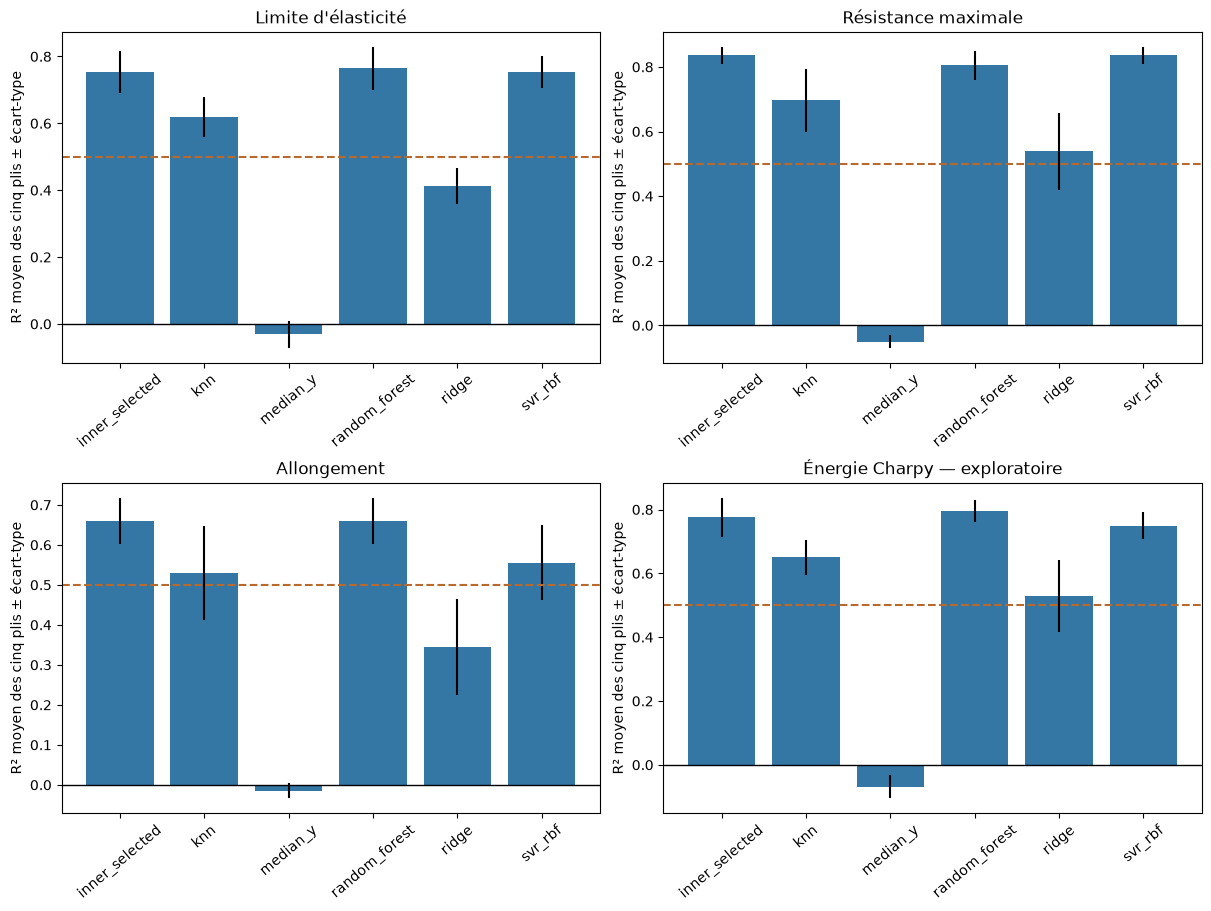

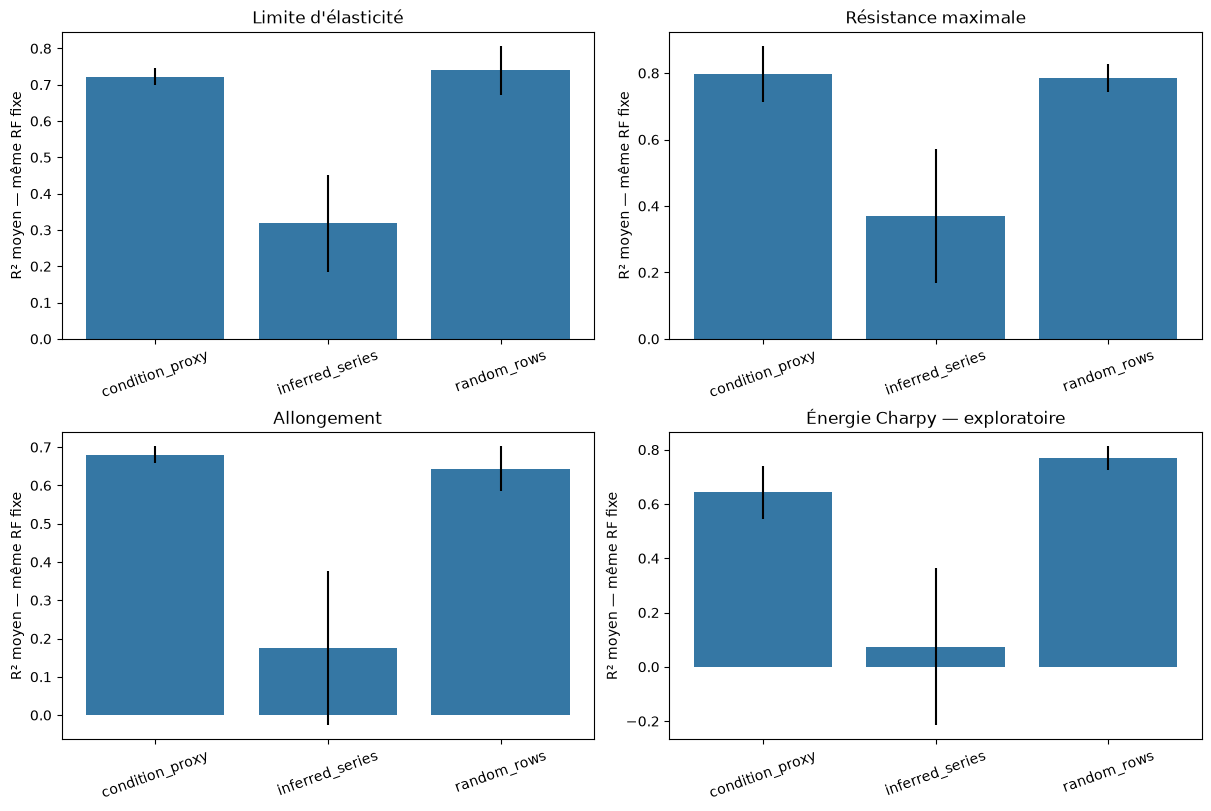

In [11]:
reload_rows=[]
loader="""import cloudpickle,pandas as pd,json,sys
from pathlib import Path
p=Path(sys.argv[1]); meta=json.loads(p.with_suffix('.json').read_text())
with p.open('rb') as f: pipeline=cloudpickle.load(f)
x=pd.read_csv(sys.argv[2])[meta['features']]
print(json.dumps(pipeline.predict(x).tolist()))
"""
for entry in chosen_final:
    target=entry['target']; family=entry['family']; path=PROJECT_ROOT/entry['path']
    probe=eligible_rows(data,target).sort_values('raw_row_id').head(10)[task_features(target)].copy()
    probe_path=OUT/f'reload_probe_{target}.csv'; probe.to_csv(probe_path,index=False)
    with path.open('rb') as stream: loaded=cloudpickle.load(stream)
    expected=loaded.predict(pd.read_csv(probe_path))
    env=dict(os.environ,OPENBLAS_NUM_THREADS='1',MPLCONFIGDIR='/tmp/salh-matplotlib')
    result=subprocess.run([sys.executable,'-c',loader,str(path),str(probe_path)],
        check=True,capture_output=True,text=True,env=env)
    actual=np.asarray(json.loads(result.stdout))
    np.testing.assert_allclose(actual,expected,rtol=1e-10,atol=1e-8)
    reload_rows.append({'target':target,'family':family,'fresh_process_verified':True,
                        'max_prediction_difference':float(np.max(np.abs(actual-expected)))})
show_saved(pd.DataFrame(reload_rows),'fresh_reload_checks.csv')
fig,axes=plt.subplots(2,2,figsize=(12,9),layout='constrained')
for ax,target in zip(axes.ravel(),TARGETS):
    g=summary.loc[summary.target==target]
    ax.bar(g.model,g.R2_mean,yerr=g.R2_sd,color='#3577a4')
    ax.axhline(.5,color='#b7692e',ls='--'); ax.axhline(0,color='black',lw=1)
    ax.tick_params(axis='x',rotation=40); ax.set(title=TARGET_NAMES[target],ylabel='R² moyen des cinq plis ± écart-type')
fig.savefig(OUT/'random_model_comparison.png',dpi=160); plt.show()
fig,axes=plt.subplots(2,2,figsize=(12,8),layout='constrained')
for ax,target in zip(axes.ravel(),TARGETS):
    g=fixed_summary.loc[fixed_summary.target==target]
    ax.bar(g.protocol,g.R2_mean,yerr=g.R2_sd,color='#3577a4')
    ax.tick_params(axis='x',rotation=20); ax.set(title=TARGET_NAMES[target],ylabel='R² moyen — même RF fixe')
fig.savefig(OUT/'grouping_comparison.png',dpi=160); plt.show()

## 9. Conclusions observées et passage à la semi-supervision

La sélection faite uniquement sur MAE interne donne les scores suivants.
Le modèle final est choisi séparément par CV5 seed1042 puis refit sur tous les
labels : sa MAE de sélection n'est pas un score de test indépendant.

| Cible | MAE moyenne externe (unité cible) | R² moyen externe | Famille du refit final |
| --- | --- | --- | --- |
| Limite d'élasticité | 31.630 | 0.755 | svr_rbf |
| UTS | 23.861 | 0.836 | svr_rbf |
| Allongement | 2.054 | 0.660 | random_forest |
| Énergie Charpy (exploratoire) | 16.461 | 0.776 | random_forest |

Les 16 variables numériques + procédé et la médiane sont la configuration de
travail retenue pour le benchmark. Ni/Cr/Mo ajoutent des colonnes, aucune ligne ;
la cohorte et les nombres de labels restent inchangés. La famille est sélectionnée
par cible et peut changer entre trains. MAE est le critère de choix, R² une métrique
complémentaire ; le meilleur classement externe ne décide pas du refit.

Les séries sont souvent plus larges qu'une soudure : 37/40, 36/39, 33/34 et 23/24
séries comportent plusieurs signatures de conditions pour YS/UTS/allongement/Charpy.
Pourtant 99–100 % des validations aléatoires retrouvent une série présente dans
le train ; environ 65 % des lignes Charpy retrouvent les mêmes conditions de
soudage (température d'essai éventuellement différente). Les deux familles de
courbes confirmées couvrent 174 points/32 conditions apparentées. Les signatures
partielles ne certifient pas des identités de soudure, et une association groupe/y
peut refléter X : ces résultats ne certifient donc pas IID.

Avec la même RF fixe, R² moyen lignes / conditions-proxy / séries :
YS 0,739 / 0,722 / 0,318 ; UTS 0,786 / 0,797 / 0,370 ;
allongement 0,644 / 0,680 / 0,175 ; Charpy 0,769 / 0,643 / 0,074.
Le transfert vers des séries exclues reste bien plus difficile. Pour la traction,
les quelques signatures répétées ne suffisent pas à expliquer cet écart ; pour
Charpy, tenir les conditions répétées ensemble réduit déjà la performance.
Les protocoles Charpy restent partiellement vérifiés : le score est exploratoire.

Les 40 pipelines sont sauvegardées avec leur prétraitement et leurs métadonnées,
cache détaché. Les quatre choisies sont vérifiées dans des processus neufs.
Les refits sur tous les labels servent à l'inférence ; pour une évaluation
semi-supervisée, reconstruire uniquement sur le train du pli.

Trois pools candidats traction : 849/878/924 lignes, qui ne représentent pas
nécessairement autant de conditions indépendantes. Charpy : **zéro** ligne sans
énergie avec température connue. Les partitions et droits d'accès sont préparés
pour le scénario **inductif**, sans X/labels de validation en apprentissage ou
pseudo-labellisation. COREG reste différé ; définir ses deux régresseurs/distances,
la sélection des pseudo-labels, paramètres, budgets et critères d'arrêt avant
son expérience. Comparer au contrôle supervisé sur les mêmes données autorisées.

Les choix 16/médiane suivent le diagnostic sur les mêmes données : ce benchmark
reste rétrospectif. Pour la nouvelle série, garder le contrôle groupé et vérifier
sur des données indépendantes. [Rapport complet](../reports/12_random_kfold_training.md).


In [12]:
pool_summary=counts[['target','labels','unlabeled_X_available']].copy()
pool_summary['semi_supervised_status']=np.where(pool_summary.unlabeled_X_available>0,
    'inductive_pool_ready_algorithm_not_implemented','no_pool_with_known_test_temperature')
show_saved(pool_summary,'semi_supervised_readiness.csv')
source_nb=nbformat_source=json.loads((PROJECT_ROOT/'notebooks/05_random_kfold.ipynb').read_text())
source_text='\n\n'.join(''.join(c['source']) for c in source_nb['cells'])
manifest={'protocol_version':'salh-random-kfold-v1','seed':SEED,'feature_set':PRIMARY_SET,
    'numeric_features':CORE16,'imputer':PRIMARY_IMPUTER,'cohort':'unchanged strict13',
    'outer':'KFold5 shuffled seed42 per target labeled rows sorted raw_row_id',
    'inner':'KFold3 shuffled seed43+outer on labeled train',
    'unlabeled_outer_seed':142,'unlabeled_inner_seeds':'1042+outer',
    'semisupervised_protocol':'inductive preparation only, no algorithm run',
    'grids':PARAM_GRIDS,'selection':'inner MAE by family and parameters; full-refit CV5 seed1042',
    'interpretation':'random-row interpolation; IID not demonstrated; retrospective after diagnostics',
    'raw_sha256':preparation_manifest['raw_sha256'],'versions':VERSIONS,
    'preparation_manifest_sha256':hashlib.sha256((DATA/'manifest.json').read_bytes()).hexdigest(),
    'diagnostic_manifest_sha256':hashlib.sha256((DIAGNOSTICS/'manifest.json').read_bytes()).hexdigest(),
    'notebook_source_sha256':hashlib.sha256(source_text.encode()).hexdigest(),
    'outer_evaluations':len(scores),'outer_selections':len(selected),'models_exported':len(artifact_rows),
    'elapsed_seconds':time.perf_counter()-STARTED,
    'files':{p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in OUT.glob('*.csv')},
    'model_files':{str(p.relative_to(PROJECT_ROOT)):hashlib.sha256(p.read_bytes()).hexdigest()
                   for p in MODELS.rglob('*') if p.is_file()}}
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False)+'\n')
display(pd.Series({k:manifest[k] for k in ['outer_evaluations','outer_selections','models_exported','elapsed_seconds']}))

,target,labels,unlabeled_X_available,semi_supervised_status
0,yield_strength,706,849,inductive_pool_ready_algorithm_not_implemented
1,uts,677,878,inductive_pool_ready_algorithm_not_implemented
2,elongation,631,924,inductive_pool_ready_algorithm_not_implemented
3,charpy_J,861,0,no_pool_with_known_test_temperature


outer_evaluations    100.000000
outer_selections      20.000000
models_exported       40.000000
elapsed_seconds      420.064866
dtype: float64